In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
model = tf.keras.applications.resnet_v2.ResNet50V2(include_top=True,weights='imagenet')
model.trainable = False
decode_predictions = tf.keras.applications.resnet_v2.decode_predictions

102869336/102869336 [==============================] - 0s 0us/step


In [ ]:
def preprocess(image):
    img = tf.keras.preprocessing.image.load_img(image, target_size=(224, 224))
    img = tf.keras.preprocessing.image.img_to_array(img)
    img = tf.cast(img, tf.float32)
    img = tf.keras.applications.resnet_v2.preprocess_input(img)
    img = img[None,...]
    return img

In [ ]:
img = 'cat.jpg'
img = preprocess(img)

pred = model.predict(img)
lab = decode_predictions(pred,top=1)[0][0][1]
conf = decode_predictions(pred,top=1)[0][0][2]
print(lab)
print(conf*100)
print('Index of label = {}'.format(pred.argmax()))

35363/35363 [==============================] - 0s 0us/step
Egyptian_cat
69.25795674324036
Index of label = 285


<function matplotlib.pyplot.show(close=None, block=None)>

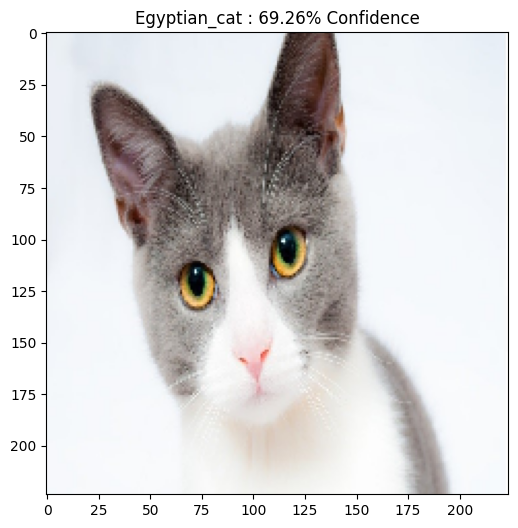

In [ ]:
plt.figure(figsize = (6,6))
plt.imshow(tf.keras.preprocessing.image.load_img('cat.jpg', target_size=(224, 224)))
plt.title('{} : {:.2f}% Confidence'.format(lab, conf*100))
plt.show

In [ ]:
loss_object = tf.keras.losses.CategoricalCrossentropy()

def get_adversarial_pattern(input_image, input_label):
  with tf.GradientTape() as tape:
    tape.watch(input_image)
    prediction = model(input_image)
    loss = loss_object(input_label, prediction)

  # Get the gradients of the loss w.r.t to the input image.
  gradient = tape.gradient(loss, input_image)
  # Get the sign of the gradients to create the perturbation
  signed_grad = tf.sign(gradient)
  return signed_grad

285


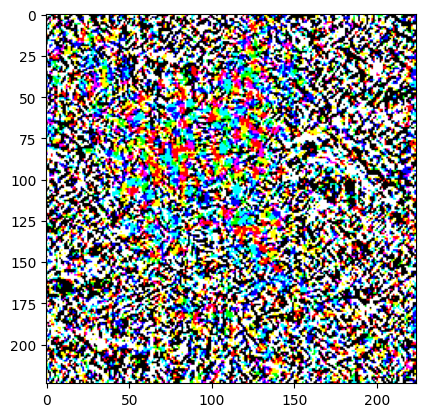

In [ ]:
# Get the input label of the image.
label_index = pred.argmax()
print(label_index)
label = tf.one_hot(label_index, pred.shape[-1])
label = tf.reshape(label, (1, pred.shape[-1]))

perturbations_true = get_adversarial_pattern(img, label)
#print(perturbations_true[0] * 0.5 + 0.5)
plt.imshow(perturbations_true[0] * 0.5 + 0.5)  # To change [-1, 1] to [0,1]

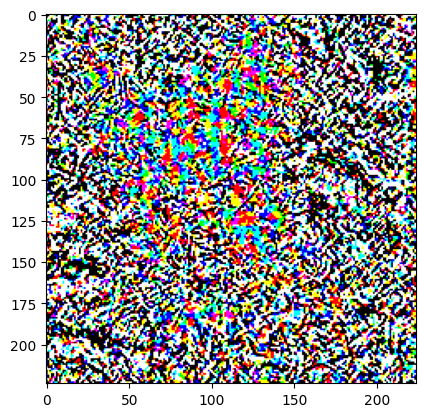

In [ ]:
#index for tabby class = 281
target_label_index = 281
target_label = tf.one_hot(target_label_index, pred.shape[-1])
target_label = tf.reshape(target_label, (1, pred.shape[-1]))

perturbations_target = get_adversarial_pattern(img, target_label)
#print(perturbations_target[0] * 0.5 + 0.5)
plt.imshow(perturbations_target[0] * 0.5 + 0.5)  # To change [-1, 1] to [0,1]

In [ ]:
def display_images(image, description):
  pred = model.predict(image)
  lab = decode_predictions(pred,top=1)[0][0][1]
  conf = decode_predictions(pred,top=1)[0][0][2]
  plt.figure()
  plt.imshow(image[0]*0.5+0.5)
  plt.title('{} \n {} : {:.4f}% Confidence'.format(description, lab, conf*100))
  plt.show()
  return conf*100,lab

1/1 [==============================] - 0s 156ms/step


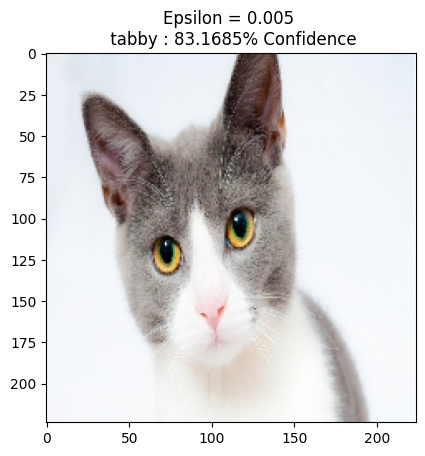

1/1 [==============================] - 0s 156ms/step


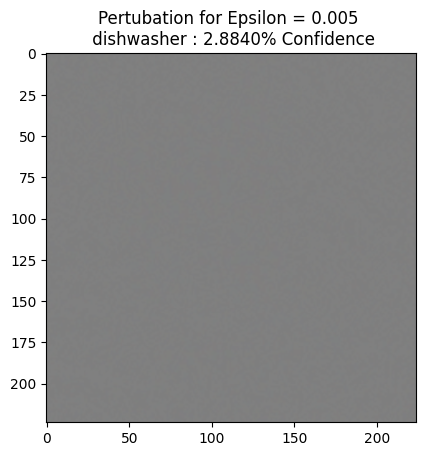

1/1 [==============================] - 0s 155ms/step


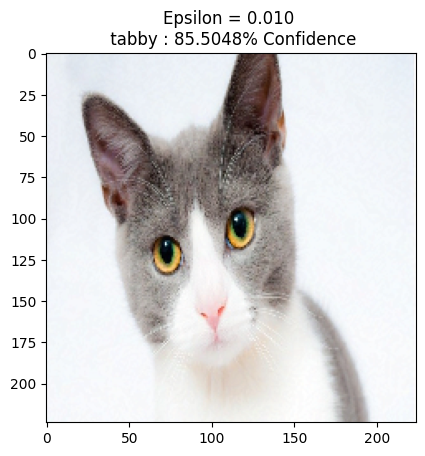

1/1 [==============================] - 0s 158ms/step


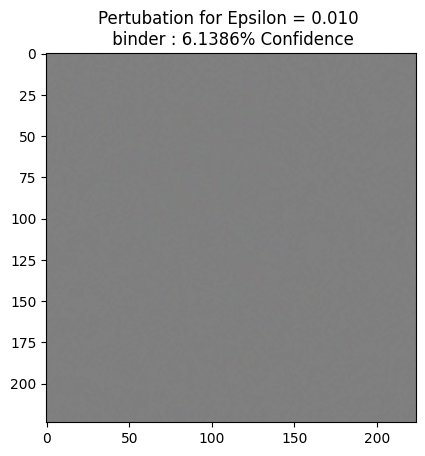

1/1 [==============================] - 0s 168ms/step


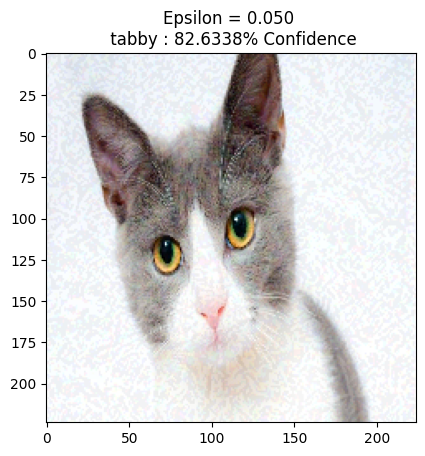

1/1 [==============================] - 0s 164ms/step


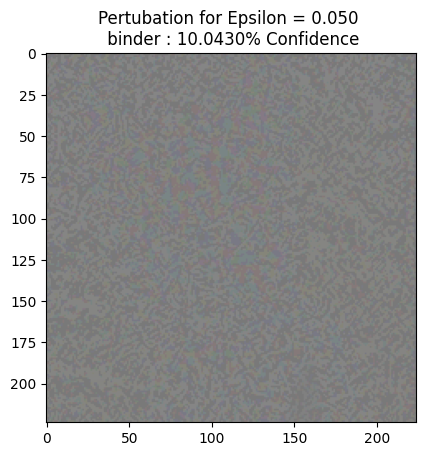

1/1 [==============================] - 0s 164ms/step


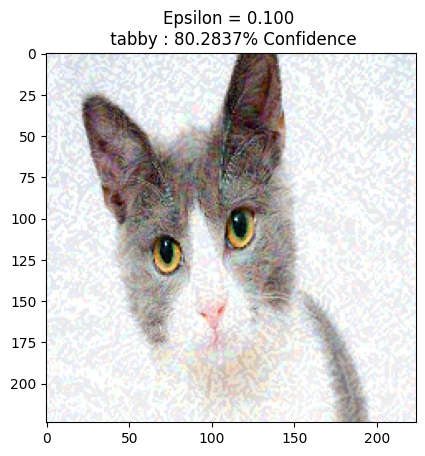

1/1 [==============================] - 0s 176ms/step


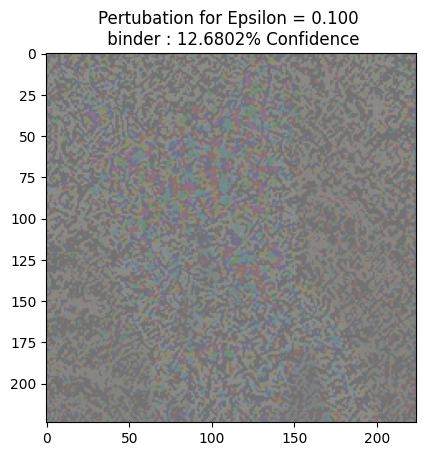

[{'tabby': 83.1684947013855, 'dishwasher': 2.8839992359280586}, {'tabby': 85.50478219985962, 'binder': 6.13856241106987}, {'tabby': 82.63378143310547, 'binder': 10.043029487133026}, {'tabby': 80.28371930122375, 'binder': 12.680180370807648}]


In [ ]:
epsilons = [0.005, 0.01, 0.05, 0.1]
descriptions = [('Epsilon = {:0.3f}'.format(eps) if eps else 'Input') for eps in epsilons]
pertubation = [('Pertubation for Epsilon = {:0.3f}'.format(eps) if eps else 'Input') for eps in epsilons]
ans=[]
for i, eps in enumerate(epsilons):
  result={}
  adv_x = img - eps*perturbations_target
  adv_x = tf.clip_by_value(adv_x, -1, 1)
  conf1,lab1=display_images(adv_x, descriptions[i])
  conf2,lab2=display_images(adv_x - img, pertubation[i])
  result[lab1]=conf1
  result[lab2]=conf2
  ans.append(result)
print(ans)

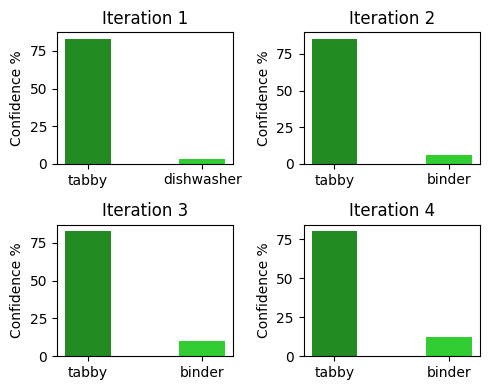

In [ ]:
# Create a 2x2 figure
fig, axs = plt.subplots(2, 2, figsize=(5,4))

# Define colors
colors = ['forestgreen', 'limegreen']

# Plot data from each dictionary
for i, data_dict in enumerate(ans):
    row = i // 2
    col = i % 2
    ax = axs[row, col]

    labels = list(data_dict.keys())
    values = list(data_dict.values())

    # Define a width for the bars
    width = 0.4

    x = np.arange(len(labels))

    ax.bar(x, values, width=width, color=colors)

    ax.set_title(f'Iteration {i + 1}')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel('Confidence %')

# Adjust layout
plt.tight_layout()

# Show the combined figure
plt.show()
